In [67]:
from figs_output import fig_output 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from datasets.Harmonized_Datasets import harmonize
import statsmodels.api as sm
import scipy

pipeline_results_dir = fig_output + "pipeline_output/"
gmt_dir = "../../data/GMT/"
hallmark_gmt = gmt_dir + "h.all.v2026.1.Hs.symbols.gmt"

In [37]:
def get_mutation_burden(samples, mutation_burden_df):
    result = {}
    for sample in samples:
        #count = 0
        #for row in mutation_burden_df.index:
        #    if mutation_burden_df.loc[row]['sampleID'] == sample:
        #        count+=1
        #result[sample] = count 
        #print(sample in mutation_burden_df['sampleID'])
        result[sample] = len(mutation_burden_df[mutation_burden_df.index == sample].index)
        #print()

    return pd.Series(result)
        

In [38]:
mutation_df = pd.read_csv('../../data/Moffitt/Whole_Exome/MAF.maf', sep='\t')

In [39]:
cv_results= pd.read_csv(f"{pipeline_results_dir}lr_reg_cv_results.csv")
mf_ad = harmonize()['Moffitt']
expr_df = pd.read_csv("../../data/Moffitt/RNAseq/log2(FPKM+1e-3)_ProteinCodingGenes.csv").set_index("GENE").transpose()
clinical_df = pd.read_csv('../../data/Moffitt/Clinical_Metadata/moffit.csv').set_index('WES_SampleID')

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18676


In [40]:
mutation_df = mutation_df.set_index('sampleID')

In [41]:
mf_ad.obs

,ABT-199,ExVivo_SampleID,patientID,t11_14,WES_SampleID
RNA_SampleID,,,,,
SL414065,68.289579,Pt429,GDH03df143c,NaN,SL409637
SL316611,96.238950,Pt227,GDH08065638,0.0,NaN
SL399348,65.236880,Pt382,GDH087884bf,0.0,SL393230
SL242336,81.704820,Pt166,GDH0bd4be69,1.0,SL241599
SL414057,86.576130,Pt419,GDH10e17fff,NaN,SL409628
...,...,...,...,...,...
SL432596,100.000000,Pt516,GDHea79fae2,NaN,SL434811
SL425882,99.259752,Pt478,GDHefa46356,NaN,SL426500
SL240795,88.815766,Pt143,GDHf5b6b0bc,0.0,SL241566


In [42]:
wes_sample_ids = list(set(mutation_df.index) & set(mf_ad.obs['WES_SampleID']))

In [43]:
wes_sample_ids
mutation_df = mutation_df.loc[wes_sample_ids]


In [44]:
mutation_df

,chr,pos,ref,alt,REF,ALT,Variant_Type,Variant_Classification,Start,End,Hugo_Symbol,Tumor_Sample_Barcode,Chromosome,Start_Position,End_Position,Reference_Allele,Tumor_Seq_Allele2,AAChange
sampleID,,,,,,,,,,,,,,,,,,
SL241585,chr1,2511281,AC,A,AC,A,DEL,Intron,2511281,2511283,PANK4,SL241585,chr1,2511281,2511283,AC,A,[PANK4
SL241585,chr1,3872414,GAA,G,GAA,G,DEL,Intron,3872414,3872417,DFFB,SL241585,chr1,3872414,3872417,GAA,G,[DFFB
SL241585,chr1,8325425,GA,G,GA,G,DEL,Intron,8325425,8325427,SLC45A1,SL241585,chr1,8325425,8325427,GA,G,[SLC45A1
SL241585,chr1,10637821,GAA,G,GAA,G,DEL,3'UTR,10637821,10637824,CASZ1,SL241585,chr1,10637821,10637824,GAA,G,[CASZ1
SL241585,chr1,12338369,AT,A,AT,A,DEL,Intron,12338369,12338371,VPS13D,SL241585,chr1,12338369,12338371,AT,A,[VPS13D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SL374462,chrX,111757493,ATTTT,A,ATTTT,A,DEL,Intron,111757493,111757498,ALG13,SL374462,chrX,111757493,111757498,ATTTT,A,[ALG13
SL374462,chrX,124071128,CTT,C,CTT,C,DEL,Intron,124071128,124071131,STAG2,SL374462,chrX,124071128,124071131,CTT,C,[STAG2
SL374462,chrX,139789549,C,T,C,T,SNP,Intron,139789549,139789550,ATP11C,SL374462,chrX,139789549,139789550,C,T,[ATP11C


In [45]:

# how would I get a column with the sum of all non-synonymous variants
mutations = ['Frame_Shift_Ins','Frame_Shift_Del', 'Nonsense_Mutation', "In_Frame_Del", "In_Frame_Ins", 'Nonstop_Mutation']


rows_with_nonsyn_mutations = [i for i in range(len(mutation_df.index)) if mutation_df.iloc[i]['Variant_Classification'] in mutations]

mutation_burden_df = mutation_df.iloc[rows_with_nonsyn_mutations]


In [92]:
mutation_df.columns

Index(['chr', 'pos', 'ref', 'alt', 'REF', 'ALT', 'Variant_Type',
       'Variant_Classification', 'Start', 'End', 'Hugo_Symbol',
       'Tumor_Sample_Barcode', 'Chromosome', 'Start_Position', 'End_Position',
       'Reference_Allele', 'Tumor_Seq_Allele2', 'AAChange'],
      dtype='str')

In [91]:
mutation_df[mutation_df['Hugo_Symbol'] == 'CCND1']

,chr,pos,ref,alt,REF,ALT,Variant_Type,Variant_Classification,Start,End,Hugo_Symbol,Tumor_Sample_Barcode,Chromosome,Start_Position,End_Position,Reference_Allele,Tumor_Seq_Allele2,AAChange
sampleID,,,,,,,,,,,,,,,,,,
SL239827,chr11,69641521,T,C,T,C,SNP,Intron,69641521,69641522,CCND1,SL239827,chr11,69641521,69641522,T,C,[CCND1
SL374485,chr11,69641365,C,A,C,A,SNP,Missense_Mutation,69641365,69641366,CCND1,SL374485,chr11,69641365,69641366,C,A,p.P18T
SL374485,chr11,69641442,C,T,C,T,SNP,Silent,69641442,69641443,CCND1,SL374485,chr11,69641442,69641443,C,T,p.S43S
SL434805,chr11,69641263,A,G,A,G,SNP,5'UTR,69641263,69641264,CCND1,SL434805,chr11,69641263,69641264,A,G,[CCND1
SL434805,chr11,69641363,A,T,A,T,SNP,Missense_Mutation,69641363,69641364,CCND1,SL434805,chr11,69641363,69641364,A,T,p.Y17F
SL434805,chr11,69641418,G,A,G,A,SNP,Silent,69641418,69641419,CCND1,SL434805,chr11,69641418,69641419,G,A,p.E35E
SL434805,chr11,69643004,G,A,G,A,SNP,Intron,69643004,69643005,CCND1,SL434805,chr11,69643004,69643005,G,A,[CCND1


In [47]:
mutation_burden_column = get_mutation_burden(mf_ad.obs["WES_SampleID"], mutation_burden_df)

In [56]:
mutation_burden_column = mutation_burden_column[mutation_burden_column.index.str.startswith("SL")]

In [57]:
mf_obs = mf_ad.obs.copy()
mf_obs["RNA_SampleID"] = mf_obs.index

In [58]:
mf_obs = mf_obs.set_index("WES_SampleID")
mf_obs = mf_obs.loc[mutation_burden_column.index]

In [59]:
mf_obs

,ABT-199,ExVivo_SampleID,patientID,t11_14,RNA_SampleID
SL409637,68.289579,Pt429,GDH03df143c,NaN,SL414065
SL393230,65.236880,Pt382,GDH087884bf,0.0,SL399348
SL241599,81.704820,Pt166,GDH0bd4be69,1.0,SL242336
SL409628,86.576130,Pt419,GDH10e17fff,NaN,SL414057
SL434805,66.291761,Pt506,GDH12b19f91,NaN,SL432590
...,...,...,...,...,...
SL434811,100.000000,Pt516,GDHea79fae2,NaN,SL432596
SL426500,99.259752,Pt478,GDHefa46356,NaN,SL425882
SL241566,88.815766,Pt143,GDHf5b6b0bc,0.0,SL240795
SL239827,79.784322,Pt142,GDHf7b6f129,1.0,SL240938


In [61]:
mf_obs['mutation_burden'] = mutation_burden_column

LinregressResult(slope=np.float64(0.21899625499298328), intercept=np.float64(77.07260303823466), rvalue=np.float64(0.19328739018043384), pvalue=np.float64(0.0471241555373539), stderr=np.float64(0.1090055083895404), intercept_stderr=np.float64(2.987359623304086))


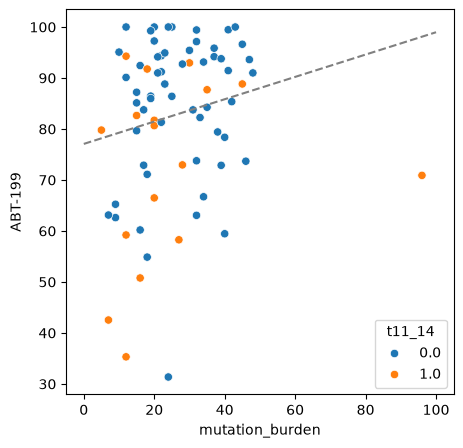

In [87]:
fig, ax = plt.subplots(1, figsize=(5,5))

res = scipy.stats.linregress(mf_obs['mutation_burden'], mf_obs['ABT-199'])

lr_x  = np.linspace(0, 100, 10)
lr_y = lr_x * res.slope + res.intercept
sns.scatterplot(mf_obs, x='mutation_burden', y='ABT-199', hue='t11_14',)

plt.plot(lr_x, lr_y, c='grey', ls='--')
print(res)
